In [1]:
!pip install openai scikit-learn pandas

In [2]:
from openai import OpenAI
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import time
import re
from google.colab import userdata

In [3]:
os.environ['OPENROUTER_APY_KEY'] = userdata.get('OPENROUTER_APY_KEY')

openai_api_key = os.getenv("OPENROUTER_APY_KEY")

# Definição de funções úteis na classificação

In [18]:
client = OpenAI(
base_url="https://openrouter.ai/api/v1",
api_key=openai_api_key,
               )

def classificar_tongyi(textos, prompt_template):

        prompt = prompt_template + "\n\n"
        for i, texto in enumerate(textos, 1):
            prompt += f"{i}. {texto}\n"
        prompt += (
                "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
                "Não explique, não justifique, não adicione nada além dos números."
            )

        completion = client.chat.completions.create(

            model="alibaba/tongyi-deepresearch-30b-a3b:free",
            messages=[
                {
                    "role": "user",
                    "content": prompt
                 }
                      ]

            )

        resp = completion.choices[0].message.content

        return resp.strip(), resp.strip()

def parse_saida(saida, expected_len):
    matches = re.findall(r"\b[01]\b", saida)
    if len(matches) == expected_len:
        return matches
    else:
        return matches + [None] * (expected_len - len(matches))


def processar_lotes(df_final, prompt_template, prompt_name, batch_size=20, sleep_time=2):
    """
    Processa lotes de textos para classificação e atualiza o DataFrame com os resultados.
    """
    df_final = df_final
    df_final[prompt_name] = None
    df_final[f'{prompt_name}_raw'] = None

    print(f"classificação com: {prompt_name}")

    for i in range(0, len(df_final), batch_size):
        try:
            lote = df_final.iloc[i:i+batch_size]["text"].tolist()
            saida, raw_saida = classificar_tongyi(lote, prompt_template)

            resultados = parse_saida(saida, len(lote))
            raw_resultados = raw_saida.split("\n")

            for j, res in enumerate(resultados):
                idx = i + j
                if idx < len(df_final):
                    if res in ["0", "1"]:
                        df_final.at[idx, prompt_name] = int(res)
                    else:
                        df_final.at[idx, prompt_name] = None
                    df_final.at[idx, f'{prompt_name}_raw'] = (
                        raw_resultados[j] if j < len(raw_resultados) else None
                    )

            time.sleep(sleep_time)

        except Exception as e:
            print(f"Erro no batch {i}–{i+batch_size} para {prompt_name}: {e}")
            time.sleep(15)

    return df_final

def plot_confusion(y_true, y_pred, titulo, path, output_dir):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    plt.figure(figsize=(5,4))
    sns.heatmap(
                cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                xticklabels=["Não ódio (0)", "Ódio (1)"],
                yticklabels=["Não ódio (0)", "Ódio (1)"]
    )
    plt.xlabel("Predição")
    plt.ylabel("Real")
    plt.title(titulo)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/confusion_matrix.png")
    plt.show()
    plt.close()

    report = classification_report(y_true, y_pred)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(report)

    print("\nRelatório de Classificação:")
    print(report)

# Carregando dataset e prompts

In [7]:
df = pd.read_csv("/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

,proportion
label,
0,0.7
1,0.3


In [8]:
zero_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("/content/hate_speech_classification_tcc/codigo/generativos/prompts/few_shot/few_shot.txt", "r").read()

# Classificação com: Zero Shot, One Shot e Few Shot

In [9]:
df_final = df.copy()

processar_lotes(df_final=df_final, prompt_template=zero_shot_prompt, prompt_name='pred_zero_shot')

classificação com: pred_zero_shot


In [10]:
processar_lotes(df_final=df_final, prompt_template=one_shot_prompt, prompt_name='pred_one_shot')

classificação com: pred_one_shot


In [19]:
processar_lotes(df_final=df_final, prompt_template=few_shot_prompt, prompt_name='pred_few_shot')

df_final.to_csv("/content/hate_speech_classification_tcc/resultados/generativos/tongyi/results_pred_tongyi.csv", index=False)

classificação com: pred_few_shot


# Avaliação das técnicas de prompt

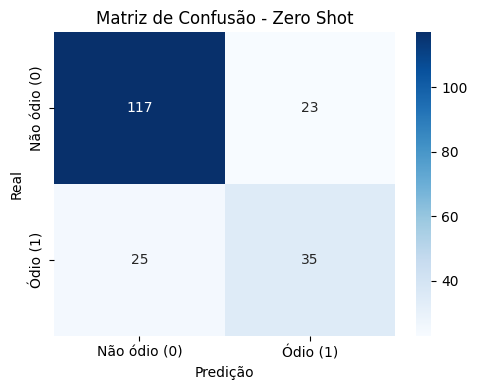


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.82      0.84      0.83       140
           1       0.60      0.58      0.59        60

    accuracy                           0.76       200
   macro avg       0.71      0.71      0.71       200
weighted avg       0.76      0.76      0.76       200



In [22]:
path = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/report_zero_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/'
y_true = df_final["label"]
y_pred = df_final["pred_zero_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Zero Shot", path, output_dir)

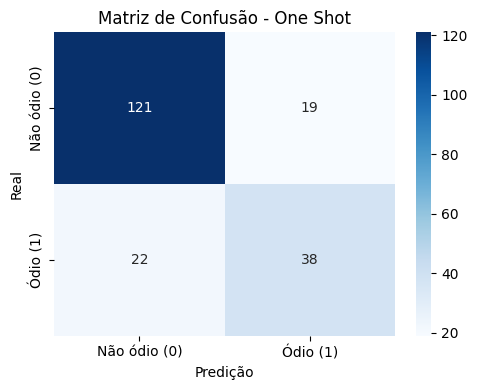


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.85      0.86      0.86       140
           1       0.67      0.63      0.65        60

    accuracy                           0.80       200
   macro avg       0.76      0.75      0.75       200
weighted avg       0.79      0.80      0.79       200



In [21]:
path = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/report_one_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/'
y_true = df_final["label"]
y_pred = df_final["pred_one_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - One Shot", path, output_dir)

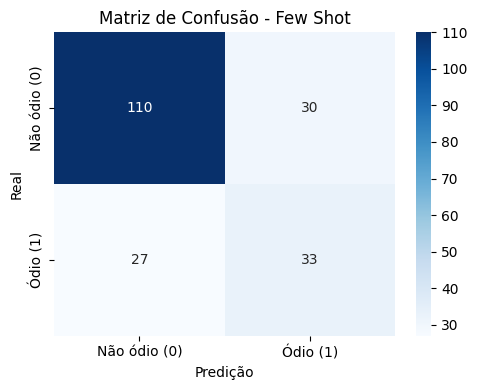


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       140
           1       0.52      0.55      0.54        60

    accuracy                           0.71       200
   macro avg       0.66      0.67      0.67       200
weighted avg       0.72      0.71      0.72       200



In [20]:
path = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/report_few_shot.txt'
output_dir = '/content/hate_speech_classification_tcc/resultados/generativos/tongyi/'
y_true = df_final["label"]
y_pred = df_final["pred_few_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Few Shot", path, output_dir)